# Практична робота №11
## Числові характеристики випадкової величини. Закон великих чисел і ЦГТ симуляцією

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Параметр експоненційного розподілу:** $\lambda = 0{,}18$ подій/хв  
**Теоретичне середнє:** $E[X] = 1/\lambda = 5{,}5556$ хв (у таблиці округлено до 5,6 хв).

**Мета:** дослідити закон великих чисел (ЗВЧ), центральну граничну теорему (ЦГТ) та стандартну похибку середнього за допомогою відтворюваної симуляції часу очікування служби підтримки.

**Умови моделювання:** $X\sim\mathrm{Exp}(\lambda)$, $E[X]=\sigma=1/\lambda$. В усіх завданнях використовується один генератор `np.random.default_rng(5)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VARIANT = 5
CITY = "Дніпро"
lam = 0.18
true_mean = 1 / lam
rng = np.random.default_rng(VARIANT)

print(f"Місто: {CITY}; варіант №{VARIANT}")
print(f"λ = {lam:.2f} подій/хв; E[X] = σ = {true_mean:.6f} хв")

Місто: Дніпро; варіант №5
λ = 0.18 подій/хв; E[X] = σ = 5.555556 хв


## Завдання 1. Перевірка закону великих чисел

Для кожного $n\in\{5,50,500,20\,000\}$ генеруємо незалежну вибірку експоненційних часів очікування та порівнюємо її середнє з відомим $E[X]=1/\lambda$.

In [2]:
sample_sizes = [5, 50, 500, 20_000]
lln_rows = []

for n in sample_sizes:
    sample = rng.exponential(scale=true_mean, size=n)
    sample_mean = sample.mean()
    lln_rows.append({
        "n": n,
        "вибіркове середнє, хв": sample_mean,
        "теоретичне E[X], хв": true_mean,
        "абсолютна різниця, хв": abs(sample_mean - true_mean),
    })

lln_table = pd.DataFrame(lln_rows)
display(lln_table.round(4))

assert lln_table.shape[0] == 4

,n,"вибіркове середнє, хв","теоретичне E[X], хв","абсолютна різниця, хв"
0,5,5.1087,5.5556,0.4469
1,50,4.6249,5.5556,0.9306
2,500,5.2392,5.5556,0.3163
3,20000,5.5201,5.5556,0.0355


**Письмовий висновок (Завдання 1).** При $n=5$ середнє становить приблизно **5,1087 хв**, відхилення від теоретичного — **0,4469 хв**. Для $n=50$ відхилення тимчасово зростає до **0,9306 хв**: закон великих чисел **не гарантує**, що похибка строго зменшуватиметься на кожному кроці конкретної симуляції. При $n=500$ відхилення становить близько **0,3163 хв**, а при $n=20\,000$ — лише **0,0355 хв**. Загальна тенденція: за великого $n$ вибіркове середнє наближається до $E[X]\approx 5,5556$ хв.

## Завдання 2. Вибірковий розподіл середнього для $n=10$ і $n=300$

Для кожного розміру вибірки створюємо **10 000 незалежних вибірок** і обчислюємо одне середнє на рядок за допомогою `.mean(axis=1)`. На гістограмах показані **розподіли вибіркових середніх $\bar X$**, а не окремих часів очікування.

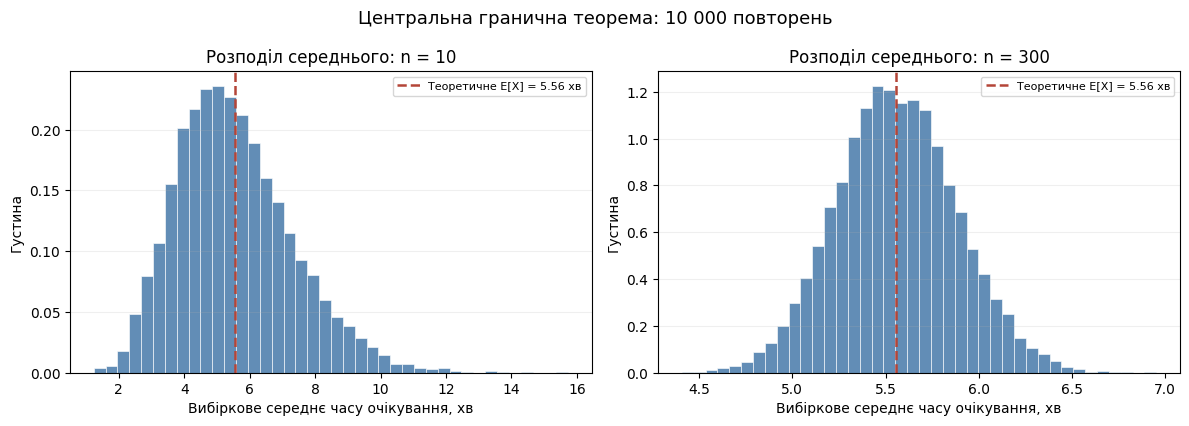

n= 10: середнє всіх x̄ = 5.5413 хв, std(x̄) = 1.7762 хв
n=300: середнє всіх x̄ = 5.5597 хв, std(x̄) = 0.3247 хв


In [3]:
n_repeats = 10_000
sample_means = {}
for n in [10, 300]:
    draws = rng.exponential(scale=true_mean, size=(n_repeats, n))
    sample_means[n] = draws.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, n in zip(axes, [10, 300]):
    values = sample_means[n]
    ax.hist(values, bins=40, density=True, edgecolor="white", linewidth=0.5,
            color="#4679A9", alpha=0.85)
    ax.axvline(true_mean, color="#B44538", linestyle="--", linewidth=1.8,
               label=f"Теоретичне E[X] = {true_mean:.2f} хв")
    ax.set_title(f"Розподіл середнього: n = {n}")
    ax.set_xlabel("Вибіркове середнє часу очікування, хв")
    ax.set_ylabel("Густина")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Центральна гранична теорема: 10 000 повторень", fontsize=13)
fig.tight_layout()
plt.show()

for n in [10, 300]:
    values = sample_means[n]
    print(f"n={n:3d}: середнє всіх x̄ = {values.mean():.4f} хв, "
          f"std(x̄) = {values.std():.4f} хв")

**Письмовий висновок (Завдання 2).** Для $n=10$ гістограма вибіркових середніх ще **помітно правосторонньо скошена**; для $n=300$ вона вже значно **симетричніша та дзвоноподібна** і сильніше зосереджена біля $5,56$ хв. Це узгоджується з ЦГТ: хоча окремі часи очікування мають скошений експоненційний розподіл, розподіл $\bar X$ стає приблизно нормальним зі збільшенням $n$.

## Завдання 3. Стандартна похибка: теорія проти симуляції

Для експоненційного розподілу $\sigma=1/\lambda$, отже теоретична стандартна похибка середнього:

$$SE(\bar X)=\frac{\sigma}{\sqrt{n}}=\frac{1/\lambda}{\sqrt n}. $$

Для $n=10$ і $n=300$ повторно використовуємо результати попереднього завдання; для $n=30$ та $n=100$ створюємо додаткові 10 000 вибірок. Виміряне `.std(ddof=0)` — стандартне відхилення *симульованого розподілу середніх*.

In [4]:
for n in [30, 100]:
    sample_means[n] = rng.exponential(
        scale=true_mean, size=(n_repeats, n)
    ).mean(axis=1)

se_rows = []
for n in [10, 30, 100, 300]:
    se = true_mean / np.sqrt(n)
    measured_std = sample_means[n].std(ddof=0)
    se_rows.append({
        "n": n,
        "теоретична SE, хв": se,
        "виміряна std(x̄), хв": measured_std,
        "абсолютна різниця, хв": abs(se - measured_std),
        "відносна різниця, %": abs(se - measured_std) / se * 100,
    })

se_table = pd.DataFrame(se_rows)
display(se_table.round(4))
assert (se_table["відносна різниця, %"] < 5).all()

,n,"теоретична SE, хв","виміряна std(x̄), хв","абсолютна різниця, хв","відносна різниця, %"
0,10,1.7568,1.7762,0.0194,1.1057
1,30,1.0143,1.0236,0.0093,0.9204
2,100,0.5556,0.5525,0.0031,0.5571
3,300,0.3208,0.3247,0.0039,1.2159


**Письмовий висновок (Завдання 3).** Теоретичні SE для $n=10,30,100,300$ дорівнюють відповідно близько **1,7568; 1,0143; 0,5556; 0,3208 хв**. Емпіричні стандартні відхилення з 10 000 повторень дуже близькі до цих величин (різниця становить лише кілька відсотків або менше). Зі збільшенням $n$ **розкид вибіркових середніх зменшується**, як передбачає формула $SE=\sigma/\sqrt n$. Незначні розходження зумовлені випадковістю симуляції й скінченною кількістю повторень.

## Завдання 4. Закон убуваючої віддачі

Порівнюємо $n=25$ і $n=100$: кількість спостережень зростає вчетверо.

In [5]:
se_25 = true_mean / np.sqrt(25)
se_100 = true_mean / np.sqrt(100)
print(f"SE для n=25:  {se_25:.6f} хв")
print(f"SE для n=100: {se_100:.6f} хв")
print(f"SE(25) / SE(100) = {se_25 / se_100:.1f}")
print("Обсяг вибірки збільшився у", 100 // 25, "рази")
assert np.isclose(se_25 / se_100, 2)

SE для n=25:  1.111111 хв
SE для n=100: 0.555556 хв
SE(25) / SE(100) = 2.0
Обсяг вибірки збільшився у 4 рази


**Письмовий висновок (Завдання 4).** Стандартна похибка зменшилася з **1,1111 хв** до **0,5556 хв**, тобто рівно **вдвічі**, хоча вибірка збільшилася **вчетверо**. Причина: $SE$ обернено пропорційна **квадратному кореню** з $n$, а $\sqrt{100/25}=\sqrt 4=2$. Щоб зменшити SE у 2 рази, потрібно в 4 рази більше спостережень, а не в 2.

## Завдання 5 (додаткове). Вплив кількості повторень `n_repeats`

Для того самого розміру вибірки $n=10$ зіставляємо **50** повторень і **10 000** повторень. Для чесного порівняння використаємо однакові межі інтервалів та осі $X$.

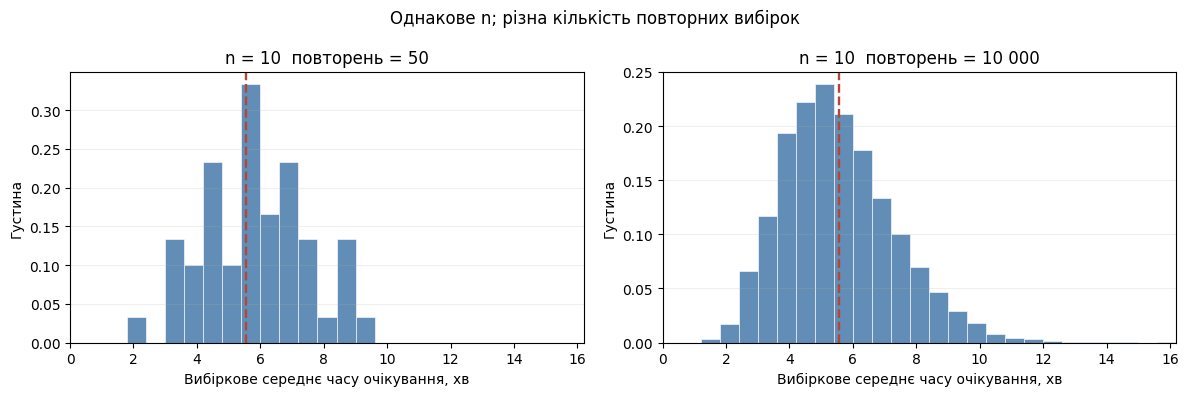

In [6]:
small_repeats = 50
means_50 = rng.exponential(scale=true_mean, size=(small_repeats, 10)).mean(axis=1)
means_10000 = sample_means[10]

# Спільні інтервали й масштаб обох графіків, щоб форму було зручно зіставити.
common_edges = np.linspace(0, max(means_50.max(), means_10000.max()) * 1.03, 28)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, arr, repeats in zip(axes, [means_50, means_10000], [50, 10_000]):
    ax.hist(arr, bins=common_edges, density=True, edgecolor="white", linewidth=0.5,
            color="#4679A9", alpha=0.85)
    ax.axvline(true_mean, color="#B44538", linestyle="--", linewidth=1.7)
    ax.set_title(f"n = 10, повторень = {repeats:,}".replace(",", " "))
    ax.set_xlabel("Вибіркове середнє часу очікування, хв")
    ax.set_ylabel("Густина")
    ax.set_xlim(common_edges[0], common_edges[-1])
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Однакове n; різна кількість повторних вибірок")
fig.tight_layout()
plt.show()

**Письмовий висновок (Завдання 5).** За 50 повторень гістограма нерівна, окремі стовпці можуть бути порожніми або непропорційно високими. За 10 000 повторень загальна скошена форма помітно стабільніша та гладша. **`n`** визначає, *який саме* розподіл має середнє (його форму та SE), тоді як **`n_repeats`** визначає, *наскільки точно ми візуалізуємо цей розподіл* через частоти в гістограмі. Якщо збільшити лише кількість повторень, теоретична SE від цього не зміниться.

## Відповіді на контрольні питання

**1. Чим закон великих чисел відрізняється від центральної граничної теореми?**  
Закон великих чисел відповідає на питання **«куди прямує вибіркове середнє?»**: за збільшення $n$ величина $\bar X$ наближається до математичного сподівання $E[X]=1/\lambda$. Центральна гранична теорема відповідає на питання **«яка форма розподілу $\bar X$ і який його масштаб розкиду?»**: за достатньо великого $n$ стандартизоване середнє $(\bar X-\mu)/(\sigma/\sqrt n)$ наближено має стандартний нормальний розподіл, а його стандартна похибка дорівнює $\sigma/\sqrt n$. ЗВЧ — про збіжність, ЦГТ — про форму випадкових коливань навколо $\mu$.

**2. Чому вихідний розподіл обрано скошеним, а не нормальним?**  
Експоненційний розподіл має велику праву асиметрію. На його прикладі особливо добре видно, що **розподіл вибіркового середнього** з наближенням $n$ до великих значень стає дзвоноподібним, хоча **розподіл окремих спостережень** не є нормальним. Якби вихідні дані вже були нормальними, середнє мало б нормальний розподіл за будь-якого $n$ і перехід форми не було б так наочно видно.

**3. Чому стандартна похибка спадає як $1/\sqrt n$, а не як $1/n$?**  
Для незалежних однаково розподілених спостережень дисперсія середнього $\mathrm{Var}(\bar X)=\sigma^2/n$. Стандартна похибка — це **корінь із дисперсії**, тому $SE(\bar X)=\sigma/\sqrt n$. Практично це означає закон убуваючої віддачі: щоб удвічі зменшити стандартну похибку, обсяг вибірки потрібно **збільшити вчетверо** (наприклад, з 25 до 100).

## Загальний висновок

Для служби підтримки м. **Дніпро** з $\lambda=0,18$ подій/хв теоретичне середнє очікування становить $5,5556$ хв. Симуляція демонструє наближення $\bar X$ до цієї величини зі зростанням $n$, поступове набуття дзвоноподібної форми розподілом середнього та зменшення стандартної похибки за законом $1/\sqrt n$. Усі обов'язкові завдання **1–4** та додаткове **5** виконані.